# Лабораторная работа №3. Кластеризация данных
**Дисциплина:** Системы искусственного интеллекта и машинное обучение  
**Датасет:** Iris, исправленная встроенная версия scikit-learn.  
**Методы:** K-means и агломеративная кластеризация Ward.

Цель: оценить структуру данных без учителя, подобрать k по внутренним метрикам, сравнить разбиения и интерпретировать группы. Известные виды используются лишь для внешней оценки после выбора k. Запуск: Run All. Требуются numpy, pandas, scipy, matplotlib, scikit-learn, jupyter.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from scipy.stats import shapiro
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score, rand_score,
    adjusted_rand_score, normalized_mutual_info_score,
    pair_confusion_matrix)
import sklearn, scipy, matplotlib, sys
from threadpoolctl import threadpool_limits
from IPython.display import display
SEED = 42
OUT = Path('outputs')
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
print('Python:', sys.version.split()[0], 'sklearn:', sklearn.__version__,
      'pandas:', pd.__version__, 'numpy:', np.__version__,
      'scipy:', scipy.__version__, 'matplotlib:', matplotlib.__version__)

Python: 3.12.10 sklearn: 1.9.1 pandas: 3.1.1 numpy: 2.5.5 scipy: 1.18.1 matplotlib: 3.11.2


## 1. Загрузка и дескриптивный анализ
Встроенная версия `load_iris` исправляет две записи исходного UCI. Признаки — длина и ширина чашелистика и лепестка (см). Метки видов отделены. Совпадающие измерения сохраняем: одинаковые округлённые значения могут принадлежать разным растениям.

Размер исходной таблицы: (150, 5) ; признаков: 4
Пропуски: 0 ; повторяющиеся векторы: 1
Типы признаков:


,dtype
Длина чашел.,float64
Ширина чашел.,float64
Длина леп.,float64
Ширина леп.,float64


,count,mean,std,min,25%,50%,75%,max
Длина чашел.,150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
Ширина чашел.,150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4
Длина леп.,150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9
Ширина леп.,150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5


,Асимметрия,W,p
Длина чашел.,0.314911,0.976090,0.010181
Ширина чашел.,0.318966,0.984918,0.101154
Длина леп.,-0.274884,0.876268,0.000000
Ширина леп.,-0.102967,0.901835,0.000000


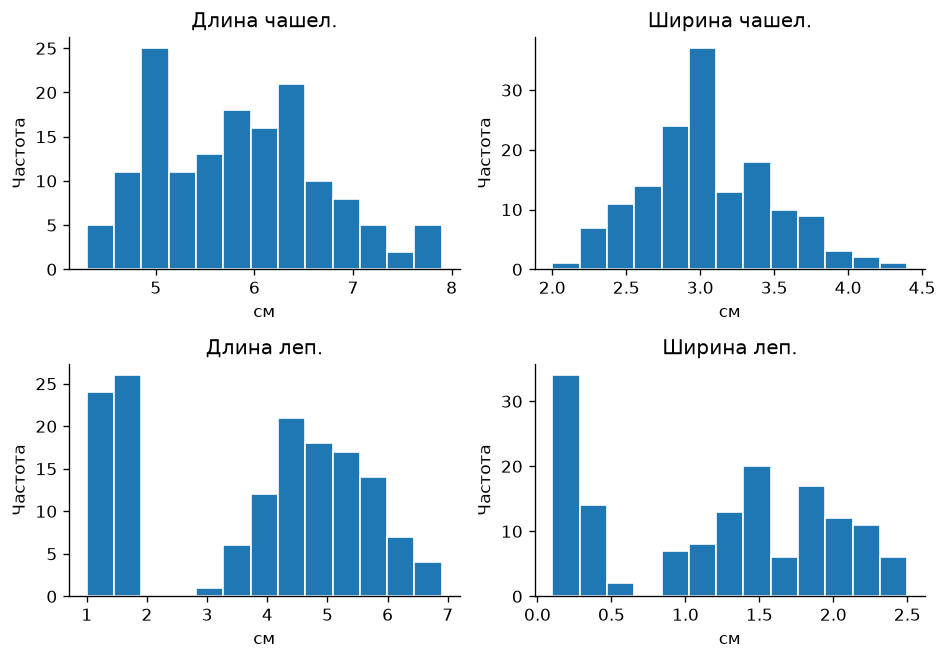

In [2]:
bunch = load_iris(as_frame=True)
X0 = bunch.data.copy()
X0.columns = ['Длина чашел.', 'Ширина чашел.', 'Длина леп.', 'Ширина леп.']
y0 = bunch.target.copy()
names = dict(enumerate(bunch.target_names))
features = list(X0.columns)
data = X0.assign(species=y0.map(names))
data.to_csv(OUT / 'iris.csv', index=False)
print('Размер исходной таблицы:', data.shape, '; признаков:', X0.shape[1])
print('Пропуски:', int(X0.isna().sum().sum()),
      '; повторяющиеся векторы:', X0.duplicated().sum())
print('Типы признаков:')
display(X0.dtypes.to_frame('dtype'))
desc = X0.describe().T
# Shapiro–Wilk: H0 — нормальное распределение; уровень 0,05
normality = pd.DataFrame({'Асимметрия': X0.skew(),
    'W': [shapiro(X0[c]).statistic for c in features],
    'p': [shapiro(X0[c]).pvalue for c in features]})
display(desc.round(3)); display(normality.round(6))
desc.to_csv(OUT / 'descriptive.csv')
normality.to_csv(OUT / 'normality.csv')
fig, axes = plt.subplots(2, 2, figsize=(8, 5.6))
for c, ax in zip(features, axes.ravel()):
    ax.hist(X0[c], bins=13, edgecolor='white')
    ax.set(title=c, xlabel='см', ylabel='Частота')
save(fig, '01_histograms')

## 2. Выбросы и применимость
Правило Тьюки: границы Q1−1,5·IQR и Q3+1,5·IQR по каждому признаку. Используем однократное исключение строк с хотя бы одним флагом, не меняя правило после просмотра меток. Флаги не означают ошибки измерений; отдельно проверим чувствительность к их сохранению.

,Q1,Q3,Нижняя,Верхняя,Флаги
Длина чашел.,5.1,6.4,3.15,8.35,0
Ширина чашел.,2.8,3.3,2.05,4.05,4
Длина леп.,1.6,5.1,-3.65,10.35,0
Ширина леп.,0.3,1.8,-1.95,4.05,0


,Длина чашел.,Ширина чашел.,Длина леп.,Ширина леп.,исходный_индекс
15,5.7,4.4,1.5,0.4,15
32,5.2,4.1,1.5,0.1,32
33,5.5,4.2,1.4,0.2,33
60,5.0,2.0,3.5,1.0,60


Исключено: 4 ; осталось: 146


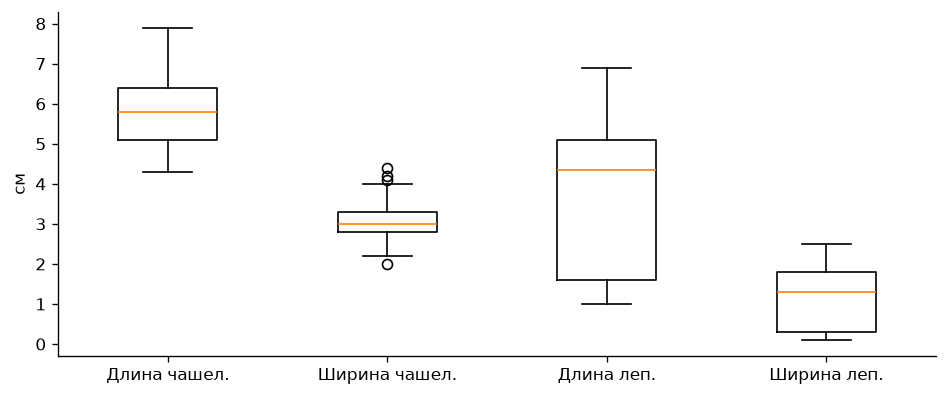

In [3]:
q1, q3 = X0.quantile(.25), X0.quantile(.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flags = X0.lt(low) | X0.gt(high)
mask = ~flags.any(axis=1)
bounds = pd.DataFrame({'Q1':q1, 'Q3':q3, 'Нижняя':low,
                       'Верхняя':high, 'Флаги':flags.sum()})
display(bounds.round(3))
display(X0.loc[~mask].assign(исходный_индекс=X0.index[~mask]))
X = X0.loc[mask].reset_index(drop=True)
y = y0.loc[mask].reset_index(drop=True)
assert not (X.lt(low) | X.gt(high)).any().any()
print('Исключено:', (~mask).sum(), '; осталось:', len(X))
bounds.to_csv(OUT / 'outliers.csv')
X0.loc[~mask].to_csv(OUT / 'excluded.csv')
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot([X0[c] for c in features], tick_labels=features)
ax.set_ylabel('см')
save(fig, '02_boxplots')

## 3. Масштабирование, информативность, структура
StandardScaler: z = (x−μ)/σ. Хотя единицы измерения одинаковы, разбросы различаются. Евклидовы расстояния без масштабирования будут сильнее зависеть от длины лепестка. Для описательной информативности рассмотрим корреляции и долю дисперсии признака, объясняемую двумя главными компонентами. Это не supervised feature importance. Разбиения строятся в полном четырёхмерном стандартизованном пространстве; PCA используется для анализа и изображения.

,Среднее,Std (ddof=0)
Длина чашел.,-0.0,1.0
Ширина чашел.,-0.0,1.0
Длина леп.,-0.0,1.0
Ширина леп.,-0.0,1.0


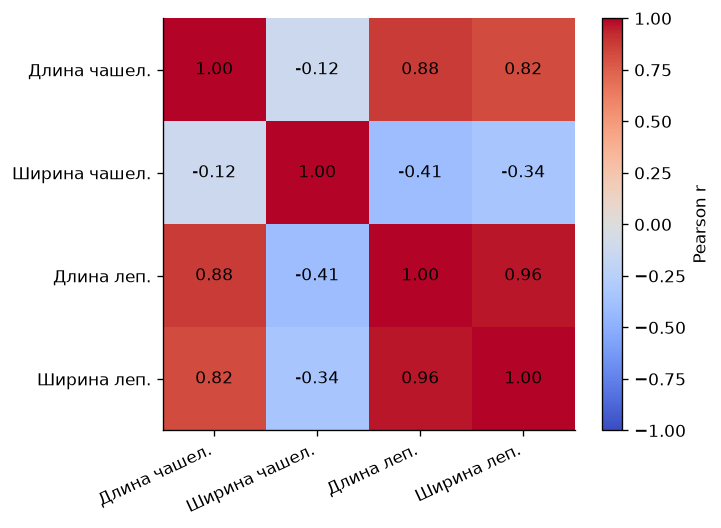

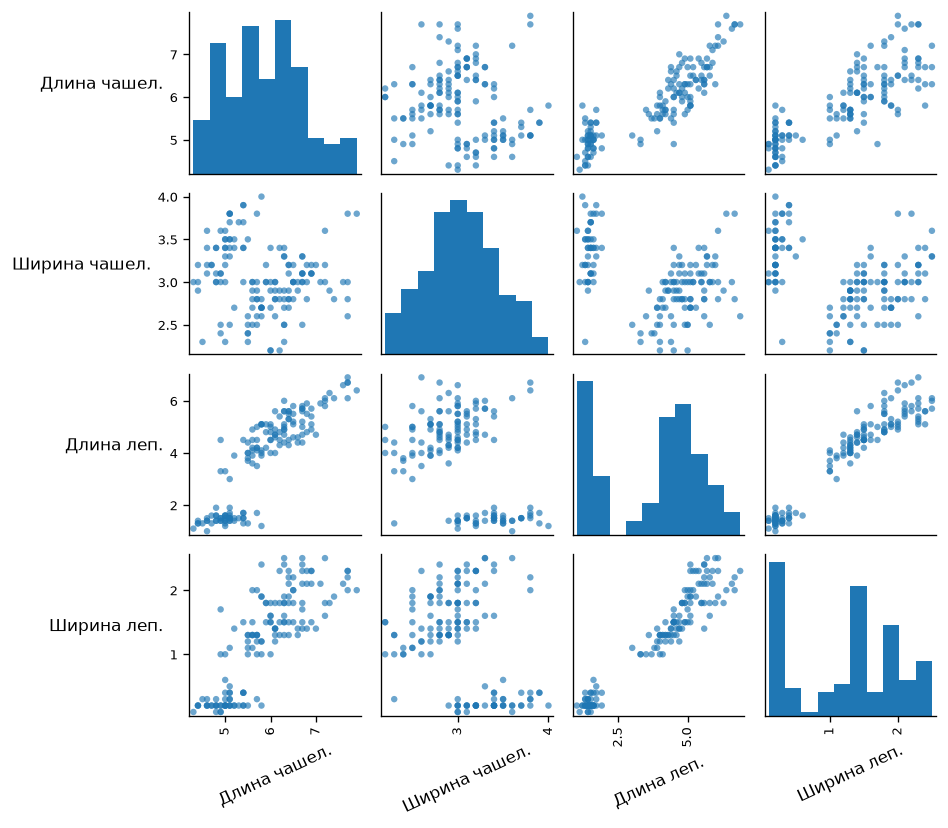

,PC1,PC2,Доля вариации в 2 PC
Длина чашел.,0.8987,0.3321,0.9179
Ширина чашел.,-0.4400,0.8939,0.9926
Длина леп.,0.9913,0.0262,0.9834
Ширина леп.,0.9635,0.0715,0.9335


PCA: [0.72808321 0.22877251]


In [4]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)
scale_check = pd.DataFrame({'Среднее':Z.mean(0), 'Std (ddof=0)':Z.std(0)},
                           index=features)
display(scale_check.round(8))
corr = X.corr()
fig, ax = plt.subplots(figsize=(6, 4.5))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(4), features, rotation=25, ha='right')
ax.set_yticks(range(4), features)
for i in range(4):
    for j in range(4): ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center')
fig.colorbar(im, ax=ax, label='Pearson r')
save(fig, '03_correlation')
axes = scatter_matrix(X, figsize=(8, 7), diagonal='hist', alpha=.65,
                      marker='o', s=15)
for ax in axes.ravel():
    ax.xaxis.label.set_rotation(25)
    ax.yaxis.label.set_rotation(0)
    ax.yaxis.label.set_horizontalalignment('right')
save(axes[0,0].figure, '04_scatter_matrix')
pca = PCA(n_components=2)
P = pca.fit_transform(Z)
# Для стандартизованных признаков: сумма квадратов корреляций с PC1 и PC2.
loadings = np.corrcoef(Z.T, P.T)[:4, 4:]
info = pd.DataFrame(loadings, index=features, columns=['PC1', 'PC2'])
info['Доля вариации в 2 PC'] = (loadings**2).sum(axis=1)
display(info.round(4)); print('PCA:', pca.explained_variance_ratio_)
info.to_csv(OUT / 'pca_information.csv')
corr.to_csv(OUT / 'correlation.csv')

## 4. Подбор k и исследование параметров
K-means минимизирует WCSS; Ward объединяет пары кластеров с минимальным приростом WCSS. По матрице рассеивания видны компактная группа малых лепестков и облако более крупных, частично перекрывающихся наблюдений. Оба алгоритма подходят для евклидовой геометрии компактных групп; Ward даёт иерархию, K-means допускает перераспределение точек. Проверяем k=2…8 на одинаковых данных. Выбор — максимальный средний силуэт; при равенстве меньший k. Метод локтя для K-means — дополнительная визуальная диагностика, а не обязательное совпадение с силуэтом. Метки видов не используются.

,Метод,k,Silhouette,CH,DB,WCSS,Среднее до центра,Среднее между центрами,Мин. между центрами,Мин. размер
0,K-means,2,0.5820,242.6495,0.5862,217.4993,1.0680,3.3912,3.3912,47
1,K-means,3,0.4670,239.3098,0.8311,134.3458,0.8634,2.9786,1.8490,43
2,K-means,4,0.4202,204.9309,0.9098,109.5782,0.7789,2.7813,1.5241,21
3,K-means,5,0.3603,196.2946,0.9214,88.9073,0.6990,2.8742,1.4134,17
4,K-means,6,0.3404,182.3659,1.0529,77.7312,0.6577,2.8684,1.1913,12
5,K-means,7,0.3605,175.7948,0.9091,67.9998,0.6234,3.0741,1.1958,3
6,K-means,8,0.3731,174.3019,0.8745,59.3412,0.5812,2.9248,0.9955,3
7,Ward,2,0.5820,242.6495,0.5862,217.4993,1.0680,3.3912,3.3912,47
8,Ward,3,0.4294,211.1418,0.8147,147.7347,0.8918,2.8181,1.8639,28
9,Ward,4,0.3878,189.5746,1.0146,116.6810,0.7963,2.6952,1.3807,25


Выбранные k: {'K-means': 2, 'Ward': 2}


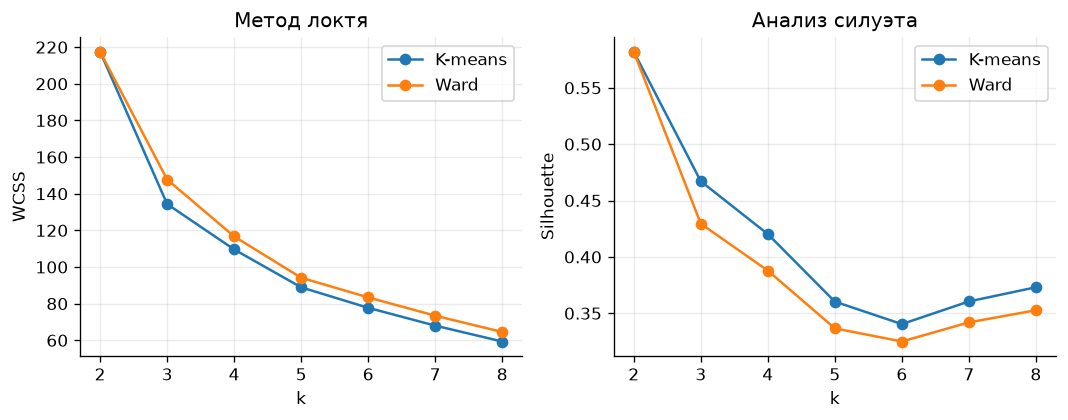

In [5]:
def fit_labels(method, k, z=Z, seed=SEED, n_init=30):
    if method == 'K-means':
        model = KMeans(n_clusters=k, n_init=n_init, random_state=seed)
    else:
        model = AgglomerativeClustering(n_clusters=k, linkage='ward')
    with threadpool_limits(limits=1):
        return model.fit_predict(z)
def centers(z, labels):
    return np.vstack([z[labels == i].mean(0) for i in np.unique(labels)])
def metrics(z, labels):
    c = centers(z, labels)
    distance = np.linalg.norm(z - c[labels], axis=1)
    return {'Silhouette':silhouette_score(z,labels),
            'CH':calinski_harabasz_score(z,labels),
            'DB':davies_bouldin_score(z,labels),
            'WCSS':float((distance**2).sum()),
            'Среднее до центра':distance.mean(),
            'Среднее между центрами':pdist(c).mean(),
            'Мин. между центрами':pdist(c).min(),
            'Мин. размер':np.bincount(labels).min()}
methods = ['K-means', 'Ward']
rows = []
for method in methods:
    for k in range(2,9):
        labels = fit_labels(method,k)
        rows.append({'Метод':method, 'k':k, **metrics(Z,labels)})
sweep = pd.DataFrame(rows)
sel = sweep.sort_values(['Silhouette','k'], ascending=[False,True])
best = {m:int(sel.loc[sel['Метод']==m,'k'].iloc[0]) for m in methods}
display(sweep.round(4)); print('Выбранные k:', best)
sweep.to_csv(OUT / 'k_sweep.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(9,3.6))
for method in methods:
    r = sweep[sweep['Метод']==method]
    axes[0].plot(r.k,r.WCSS,'o-',label=method)
    axes[1].plot(r.k,r.Silhouette,'o-',label=method)
for ax,title,ylabel in zip(axes,['Метод локтя','Анализ силуэта'],['WCSS','Silhouette']):
    ax.set(title=title,xlabel='k',ylabel=ylabel); ax.legend(); ax.grid(alpha=.25)
save(fig,'05_k_selection')

## 5. Два итоговых разбиения, дендрограмма и внутренние метрики
Для удобства интерпретации переименуем кластеры в порядке возрастания средней длины лепестка. Это лишь перенумерация, не изменение разбиения. Ward не имеет параметра centroid: центры вычисляются после обучения как средние.

,k,Silhouette,CH,DB,WCSS,Среднее до центра,Среднее между центрами,Мин. между центрами,Мин. размер
K-means,2,0.582,242.6495,0.5862,217.4993,1.068,3.3912,3.3912,47.0
Ward,2,0.582,242.6495,0.5862,217.4993,1.068,3.3912,3.3912,47.0


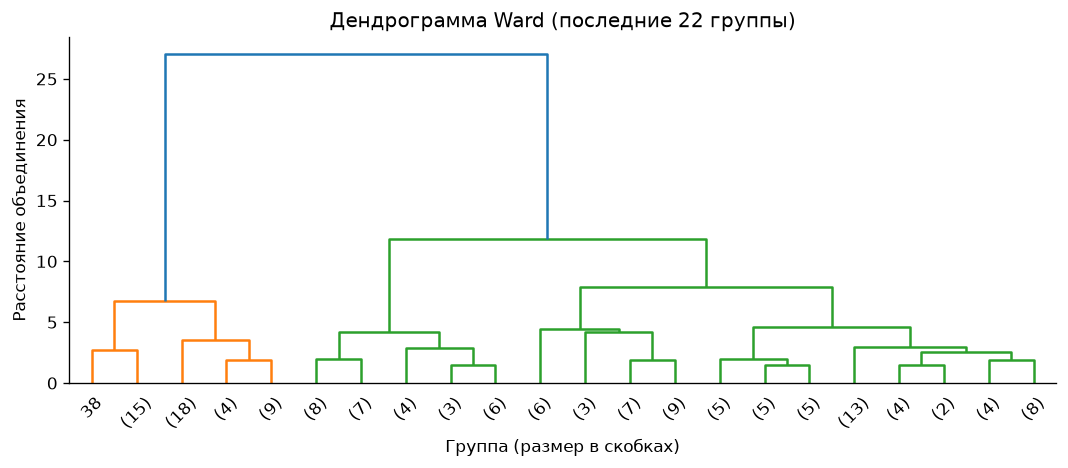

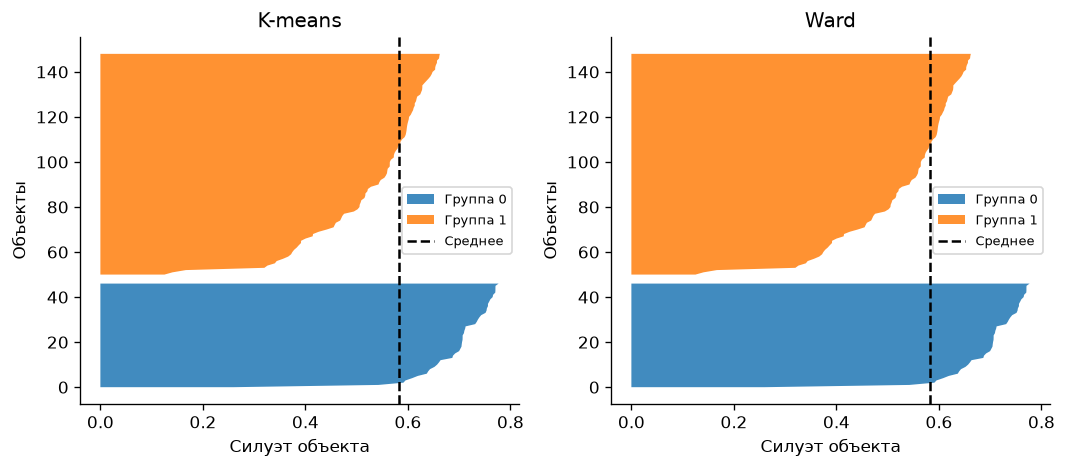

In [6]:
def ordered(labels):
    means = [(i, X.loc[labels==i, 'Длина леп.'].mean()) for i in np.unique(labels)]
    mapping = {i:j for j,(i,_) in enumerate(sorted(means,key=lambda t:t[1]))}
    return np.array([mapping[i] for i in labels])
labels_by_method = {m:ordered(fit_labels(m,best[m])) for m in methods}
comparison = pd.DataFrame({m:metrics(Z,l) for m,l in labels_by_method.items()}).T
comparison.insert(0,'k',[best[m] for m in comparison.index])
display(comparison.round(4)); comparison.to_csv(OUT/'internal_metrics.csv')
fig, ax = plt.subplots(figsize=(9,4))
dendrogram(linkage(Z,method='ward'), truncate_mode='lastp', p=22,
           show_leaf_counts=True, ax=ax)
ax.set(title='Дендрограмма Ward (последние 22 группы)',
       ylabel='Расстояние объединения',xlabel='Группа (размер в скобках)')
save(fig,'06_dendrogram')
fig, axes = plt.subplots(1,2,figsize=(9,4))
for m,ax in zip(methods,axes):
    l = labels_by_method[m]
    vals = silhouette_samples(Z,l)
    start = 0
    for i in np.unique(l):
        a = np.sort(vals[l==i]); end=start+len(a)
        ax.fill_betweenx(np.arange(start,end),0,a,alpha=.85,label=f'Группа {i}')
        start=end+3
    ax.axvline(vals.mean(),ls='--',color='black',label='Среднее')
    ax.set(title=m,xlabel='Силуэт объекта',ylabel='Объекты'); ax.legend(fontsize=8)
save(fig,'07_silhouette')

## 6. Центры, компактность, информационная значимость
Для каждого кластера вычислим средние исходные значения, среднюю евклидову дистанцию до центра и среднюю квадратичную дистанцию. Межцентровые расстояния также рассчитываются в Z-пространстве. Доля межкластерной дисперсии η² показывает, насколько признак различает уже найденные группы (не причинная значимость).

,Метод,Кластер,n,Длина чашел.,Ширина чашел.,Длина леп.,Ширина леп.,Среднее до центра,RMS до центра
0,K-means,0,47,4.977,3.377,1.462,0.247,0.786,0.926
1,K-means,1,99,6.275,2.881,4.920,1.683,1.202,1.338
2,Ward,0,47,4.977,3.377,1.462,0.247,0.786,0.926
3,Ward,1,99,6.275,2.881,4.920,1.683,1.202,1.338


,Метод,Пара,Расстояние
0,K-means,0–1,3.391
1,Ward,0–1,3.391


,K-means,Ward
Длина чашел.,0.532,0.532
Ширина чашел.,0.341,0.341
Длина леп.,0.851,0.851
Ширина леп.,0.786,0.786


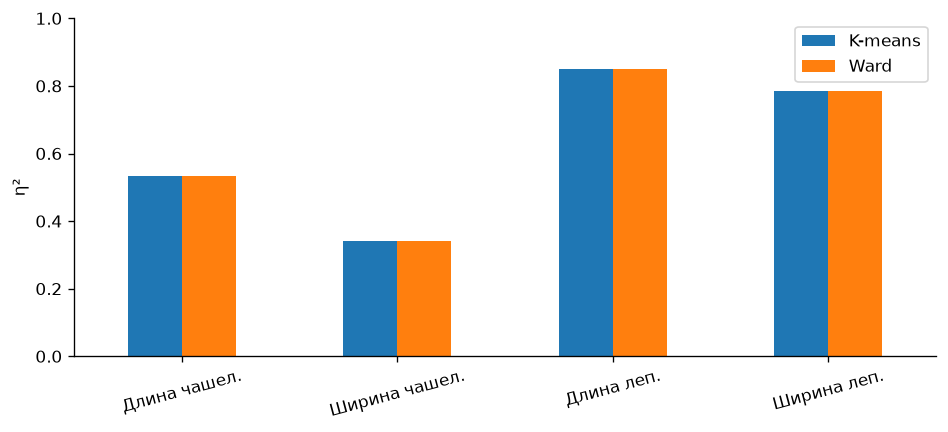

In [7]:
profiles = []; distances = []; eta = {}
for m,l in labels_by_method.items():
    c = centers(Z,l)
    d = np.linalg.norm(Z-c[l],axis=1)
    for i in np.unique(l):
        sel_i=l==i
        profiles.append({'Метод':m,'Кластер':i,'n':int(sel_i.sum()),
            **X.loc[sel_i].mean().to_dict(),
            'Среднее до центра':d[sel_i].mean(),
            'RMS до центра':np.sqrt((d[sel_i]**2).mean())})
    for i in range(len(c)):
        for j in range(i+1,len(c)):
            distances.append({'Метод':m,'Пара':f'{i}–{j}',
                              'Расстояние':np.linalg.norm(c[i]-c[j])})
    ssb = ((c-Z.mean(0))**2 * np.bincount(l)[:,None]).sum(0)
    eta[m] = ssb / ((Z-Z.mean(0))**2).sum(0)
profile = pd.DataFrame(profiles)
inter = pd.DataFrame(distances)
eta_table = pd.DataFrame(eta,index=features)
display(profile.round(3)); display(inter.round(3)); display(eta_table.round(3))
profile.to_csv(OUT/'profiles.csv',index=False)
inter.to_csv(OUT/'center_distances.csv',index=False)
eta_table.to_csv(OUT/'eta2.csv')
fig,ax=plt.subplots(figsize=(8,3.7))
eta_table.plot.bar(ax=ax,rot=15); ax.set(ylabel='η²',ylim=(0,1))
save(fig,'08_feature_relevance')

## 7. Внешняя оценка
Только теперь используем известные виды. Rand, ARI, NMI и парный Jaccard не требуют совпадения номеров кластеров с номерами классов. Парный Jaccard = TP/(TP+FP+FN), где пара объектов считается положительной при принадлежности одной группе. Дополнительно проверяем k=3 как заранее выделенный диагностический сценарий, но не заменяем им выбор по силуэту.

In [8]:
def external(y,l):
    tn, fp, fn, tp = pair_confusion_matrix(y,l).ravel()
    return {'Rand':rand_score(y,l), 'ARI':adjusted_rand_score(y,l),
            'NMI':normalized_mutual_info_score(y,l),
            'Jaccard':tp/(tp+fp+fn)}
ext=[]; crosses=[]
for m in methods:
    for k in sorted(set([best[m],3])):
        l = labels_by_method[m] if k==best[m] else ordered(fit_labels(m,k))
        ext.append({'Метод':m,'k':k,'Silhouette':silhouette_score(Z,l),**external(y,l)})
        ct=pd.crosstab(y.map(names).rename('Вид'),pd.Series(l,name='Кластер'))
        print(m,'k=',k); display(ct)
        ct.to_csv(OUT/f'cross_{m}_{k}.csv')
external_table=pd.DataFrame(ext)
display(external_table.round(4))
external_table.to_csv(OUT/'external_metrics.csv',index=False)
print('ARI между итоговыми методами:',adjusted_rand_score(*labels_by_method.values()))

K-means k= 2


Кластер,0,1
Вид,,
setosa,47,0
versicolor,0,49
virginica,0,50


K-means k= 3


Кластер,0,1,2
Вид,,,
setosa,47,0,0
versicolor,0,39,10
virginica,0,17,33


Ward k= 2


Кластер,0,1
Вид,,
setosa,47,0
versicolor,0,49
virginica,0,50


Ward k= 3


Кластер,0,1,2
Вид,,,
setosa,47,0,0
versicolor,0,26,23
virginica,0,2,48


,Метод,k,Silhouette,Rand,ARI,NMI,Jaccard
0,K-means,2,0.5820,0.7685,0.5555,0.7278,0.5870
1,K-means,3,0.4670,0.8163,0.5853,0.6419,0.5656
2,Ward,2,0.5820,0.7685,0.5555,0.7278,0.5870
3,Ward,3,0.4294,0.8252,0.6171,0.6972,0.6011


ARI между итоговыми методами: 1.0


## 8. Визуализация кластеров
Все центры проецируются тем же PCA, что и объекты. Отдельная диаграмма по двум исходным признакам облегчает биологическую интерпретацию. Истинные метки показаны только для проверки уже полученного результата.

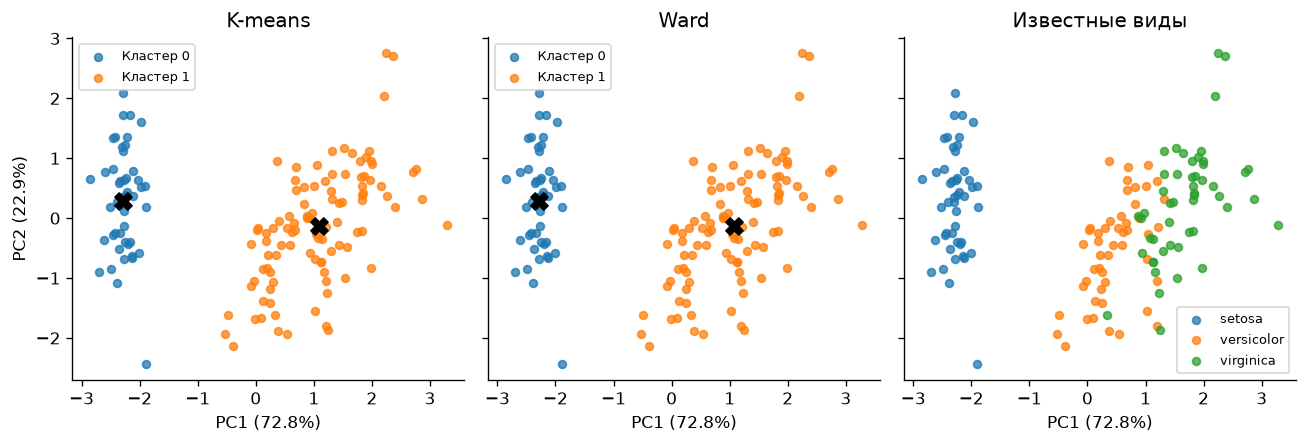

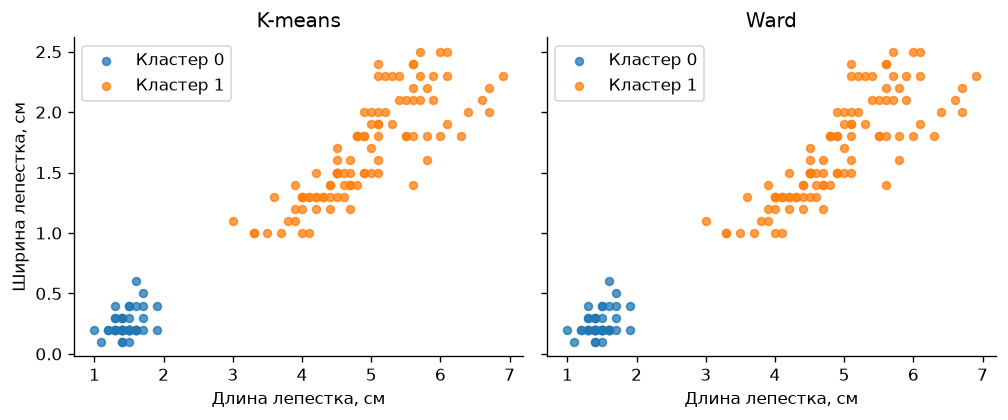

In [9]:
fig,axes=plt.subplots(1,3,figsize=(11,3.8),sharex=True,sharey=True)
for ax,(title,l) in zip(axes,[*labels_by_method.items(),('Известные виды',y.to_numpy())]):
    for i in np.unique(l):
        ax.scatter(*P[l==i].T,s=22,alpha=.75,label=names[i] if title=='Известные виды' else f'Кластер {i}')
    if title in methods:
        pc=pca.transform(centers(Z,l)); ax.scatter(*pc.T,marker='X',s=105,c='black')
    ax.set(title=title,xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})')
    ax.legend(fontsize=8)
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%})')
save(fig,'09_pca_clusters')
fig,axes=plt.subplots(1,2,figsize=(8.5,3.6),sharex=True,sharey=True)
for m,ax in zip(methods,axes):
    l=labels_by_method[m]
    for i in np.unique(l):
        a=X.loc[l==i]
        ax.scatter(a['Длина леп.'],a['Ширина леп.'],s=22,alpha=.75,label=f'Кластер {i}')
    ax.set(title=m,xlabel='Длина лепестка, см'); ax.legend()
axes[0].set_ylabel('Ширина лепестка, см')
save(fig,'10_petals_clusters')

## 9. Устойчивость к обработке выбросов и случайной инициализации
Сравним полные и рабочие данные при фиксированных выбранных k. Силуэт вычисляется отдельно на каждом наборе, а ARI на общих 146 объектах показывает устойчивость. Для K-means отдельно оценим десять случайных стартов при n_init=1 и 30.

In [10]:
Zfull=StandardScaler().fit_transform(X0)
sensitivity=[]
for m in methods:
    lfull=fit_labels(m,best[m],Zfull)
    l=labels_by_method[m]
    sensitivity.append({'Метод':m,'k':best[m],
        'Silhouette все':silhouette_score(Zfull,lfull),
        'Silhouette очищ.':silhouette_score(Z,l),
        'ARI общих объектов':adjusted_rand_score(l,lfull[mask.to_numpy()])})
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity.round(4)); sensitivity.to_csv(OUT/'outlier_sensitivity.csv',index=False)
stab=[]
for n_init in [1,30]:
    for seed in range(10):
        l=fit_labels('K-means',best['K-means'],seed=seed,n_init=n_init)
        stab.append({'n_init':n_init,'seed':seed,
             'Silhouette':silhouette_score(Z,l),
             'ARI к опоре':adjusted_rand_score(l,labels_by_method['K-means'])})
stab=pd.DataFrame(stab)
summary=stab.groupby('n_init')[['Silhouette','ARI к опоре']].agg(['mean','min','max'])
display(summary.round(4)); stab.to_csv(OUT/'stability.csv',index=False)

,Метод,k,Silhouette все,Silhouette очищ.,ARI общих объектов
0,K-means,2,0.5818,0.582,1.0000
1,Ward,2,0.5770,0.582,0.9722


Silhouette               ARI к опоре          
             mean    min    max        mean  min  max
n_init                                               
1           0.582  0.582  0.582         1.0  1.0  1.0
30          0.582  0.582  0.582         1.0  1.0  1.0

## 10. Заключение
Численные результаты выводятся непосредственно ниже. Выбранное k характеризует геометрическую структуру, а не обязательное количество ботанических видов. Сравнение по внутренним метрикам проводится без меток. Внешние метрики при k=3 приводятся для объяснения различия задач классификации и кластеризации.

In [11]:
for m in methods:
    r=comparison.loc[m]
    print(f"{m}: k={best[m]}, silhouette={r['Silhouette']:.4f}, "
          f"CH={r['CH']:.2f}, DB={r['DB']:.4f}; "
          f"sizes={np.bincount(labels_by_method[m]).tolist()}")
print('Суммарная объяснённая дисперсия PCA:',pca.explained_variance_ratio_.sum())
print('Таблицы и рисунки сохранены в',OUT.resolve())

K-means: k=2, silhouette=0.5820, CH=242.65, DB=0.5862; sizes=[47, 99]
Ward: k=2, silhouette=0.5820, CH=242.65, DB=0.5862; sizes=[47, 99]
Суммарная объяснённая дисперсия PCA: 0.9568557195230516
Таблицы и рисунки сохранены в C:\Users\Perfect_Player\Downloads\outputs


### Источники
- Fisher R. A. Iris. UCI Machine Learning Repository. DOI 10.24432/C56C76. https://archive.ics.uci.edu/dataset/53/iris
- https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html
- https://scikit-learn.org/stable/modules/clustering.html
- https://scikit-learn.org/stable/modules/preprocessing.html
- https://scikit-learn.org/stable/modules/decomposition.html#pca
- https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html